# 02 · When, where, and which trains: the shape of Caltrain lateness

Everything here uses the `clean` subset from notebook 01 (513k non-origin arrivals,
380 service days, bad-feed days masked). "Late" means more than 4 minutes behind
schedule, matching Caltrain's own on-time definition. Sample sizes are printed with
every table; shares carry 95% Wilson intervals where they matter.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import q, connect, STATION_ORDER, wilson_halfwidth
from viz import BLUE, ORANGE, AQUA, VIOLET, RED, MUTED, GRID, SEQ, DIV, DIR_COLOR, SERVICE_COLOR, note

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 120)
con = connect()
qq = lambda s: q(s, con)

## 1. Time of day × direction: two peaks, and northbound is worse in both

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


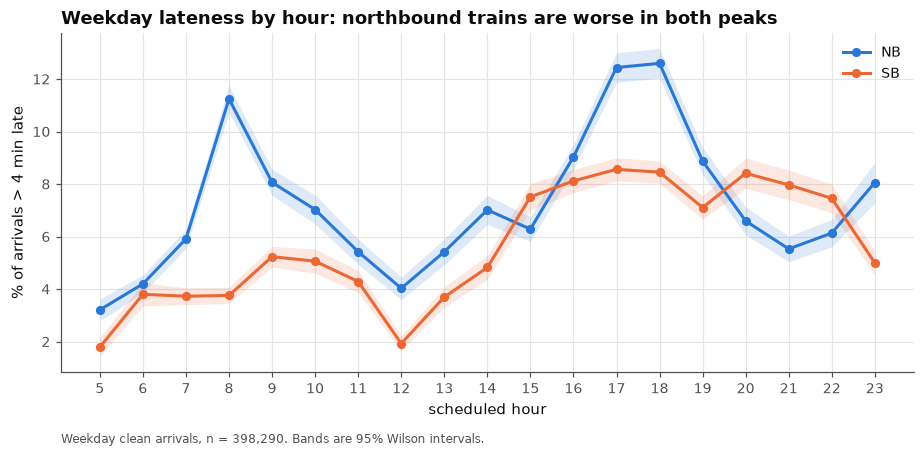

In [2]:
h = qq("""select sched_hour, direction, count(*) n, avg(late4::int) late4, avg(delay_signed) mean_delay
          from clean where weekday and sched_hour between 5 and 23 group by 1,2 order by 1,2""")
fig, ax = plt.subplots(figsize=(10, 4))
for d, g in h.groupby("direction"):
    ax.plot(g.sched_hour, g.late4 * 100, color=DIR_COLOR[d], marker="o", label=f"{d}")
    hw = wilson_halfwidth(g.late4, g.n) * 100
    ax.fill_between(g.sched_hour, (g.late4*100 - hw), (g.late4*100 + hw), color=DIR_COLOR[d], alpha=0.15, lw=0)
ax.set_xticks(range(5, 24)); ax.set_ylabel("% of arrivals > 4 min late"); ax.set_xlabel("scheduled hour")
ax.set_title("Weekday lateness by hour: northbound trains are worse in both peaks")
ax.legend(title=None); note(ax, f"Weekday clean arrivals, n = {h.n.sum():,}. Bands are 95% Wilson intervals.")
plt.show()

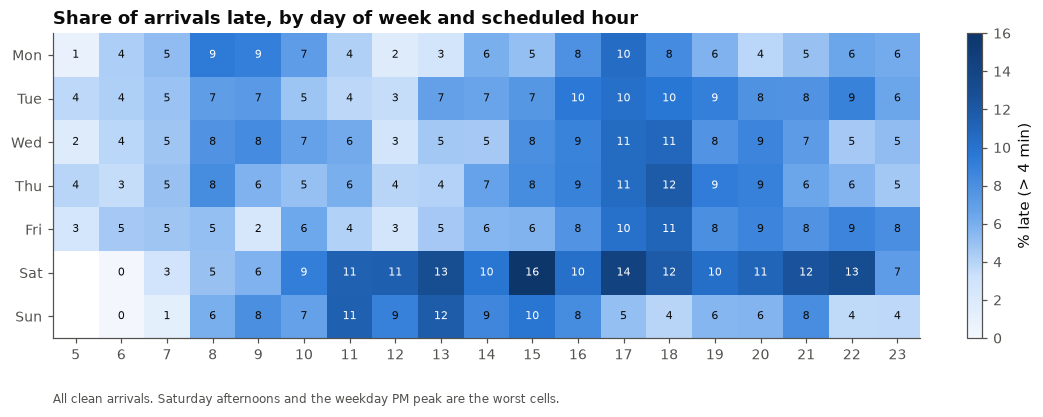

In [3]:
# Heatmap: hour × day-of-week, both directions pooled
hm = qq("""select dow, sched_hour, count(*) n, avg(late4::int) late4 from clean where sched_hour between 5 and 23 group by 1,2""")
piv = hm.pivot(index="dow", columns="sched_hour", values="late4") * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(piv.values, cmap=SEQ, aspect="auto", vmin=0, vmax=16)
ax.set_yticks(range(7)); ax.set_yticklabels(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns); ax.grid(False)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7, color="white" if v > 9 else "#0b0b0b")
plt.colorbar(im, ax=ax, label="% late (> 4 min)", fraction=0.025)
ax.set_title("Share of arrivals late, by day of week and scheduled hour")
note(ax, "All clean arrivals. Saturday afternoons and the weekday PM peak are the worst cells.")
plt.show()

## 2. Saturday is the least reliable day

Not what a commuter would guess: the pooled late share on Saturdays is higher than on
any weekday. The per-day view shows *why*: the typical Saturday is only slightly worse,
but one Saturday in five is a bad day (> 15% of arrivals late) versus one weekday in
fourteen. Both directions suffer equally on Saturdays, unlike weekdays where northbound
dominates, which is consistent with weekend track work (single-tracking) rather than
the weekday congestion pattern.

In [4]:
qq("""select case when dow<=5 then 'weekday' when dow=6 then 'Saturday' else 'Sunday' end day_type, count(*) n, count(distinct date) ndays,
          round(avg(late4::int),3) late4_pooled, round(avg(late15::int),4) late15_pooled,
          round(avg(case when direction='NB' then late4::int end),3) late4_nb, round(avg(case when direction='SB' then late4::int end),3) late4_sb
   from clean group by 1 order by 1 desc""")

,day_type,n,ndays,late4_pooled,late15_pooled,late4_nb,late4_sb
0,weekday,398974,272,0.067,0.0101,0.076,0.059
1,Sunday,60574,56,0.071,0.0082,0.061,0.081
2,Saturday,53610,52,0.107,0.0178,0.099,0.115


In [5]:
pd_ = qq("select date, dow, avg(late4::int) late4, count(*) n from clean group by 1,2")
pd_["type"] = np.where(pd_.dow <= 5, "weekday", np.where(pd_.dow == 6, "Saturday", "Sunday"))
summ = pd_.groupby("type").late4.agg(ndays="size", median="median", p75=lambda s: s.quantile(.75),
                                     share_over_15pct=lambda s: (s > .15).mean(), share_over_25pct=lambda s: (s > .25).mean()).round(3)
summ

,ndays,median,p75,share_over_15pct,share_over_25pct
type,,,,,
Saturday,52,0.067,0.122,0.192,0.058
Sunday,56,0.058,0.086,0.107,0.018
weekday,272,0.057,0.081,0.074,0.011


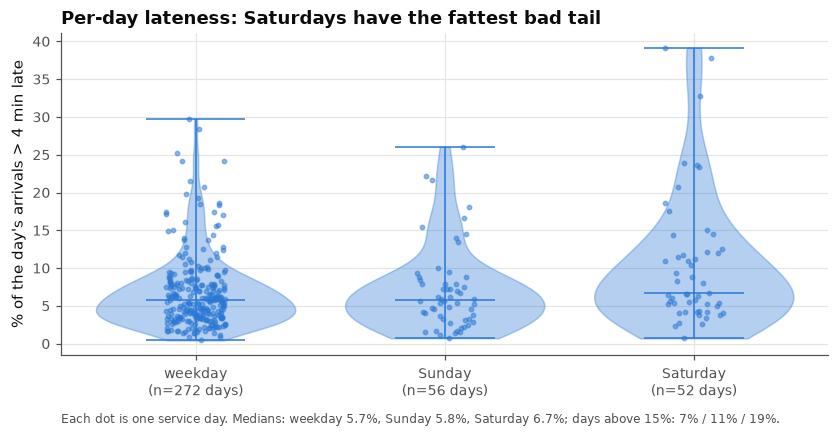

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.8))
order = ["weekday", "Sunday", "Saturday"]
data = [pd_.loc[pd_.type == t, "late4"].values * 100 for t in order]
parts = ax.violinplot(data, positions=range(3), showmedians=True, widths=0.8)
for b in parts["bodies"]:
    b.set_facecolor(BLUE); b.set_alpha(0.35); b.set_edgecolor(BLUE)
for k in ("cmedians", "cmins", "cmaxes", "cbars"):
    parts[k].set_color(BLUE); parts[k].set_linewidth(1)
rng = np.random.default_rng(0)
for i, t in enumerate(order):
    v = pd_.loc[pd_.type == t, "late4"].values * 100
    ax.scatter(i + rng.uniform(-0.12, 0.12, len(v)), v, s=8, color=BLUE, alpha=0.5)
ax.set_xticks(range(3)); ax.set_xticklabels([f"{t}\n(n={summ.loc[t,'ndays']} days)" for t in order])
ax.set_ylabel("% of the day's arrivals > 4 min late")
ax.set_title("Per-day lateness: Saturdays have the fattest bad tail")
note(ax, "Each dot is one service day. Medians: weekday 5.7%, Sunday 5.8%, Saturday 6.7%; days above 15%: 7% / 11% / 19%.")
plt.show()

In [7]:
qq("""select date, count(*) n, round(avg(late4::int),3) late4, round(avg(late15::int),3) late15 from clean where dow=6 group by 1 order by late4 desc limit 8""")

,date,n,late4,late15
0,2025-10-04,1106,0.392,0.090
1,2026-05-23,1061,0.378,0.017
2,2026-01-03,1014,0.328,0.193
3,2026-09-12,1121,0.239,0.040
4,2026-08-29,1006,0.237,0.025
5,2026-06-06,1118,0.234,0.000
6,2026-03-14,993,0.207,0.104
7,2026-04-04,1062,0.186,0.012


## 3. Month by month: no trend, but summer 2026 was the calmest stretch

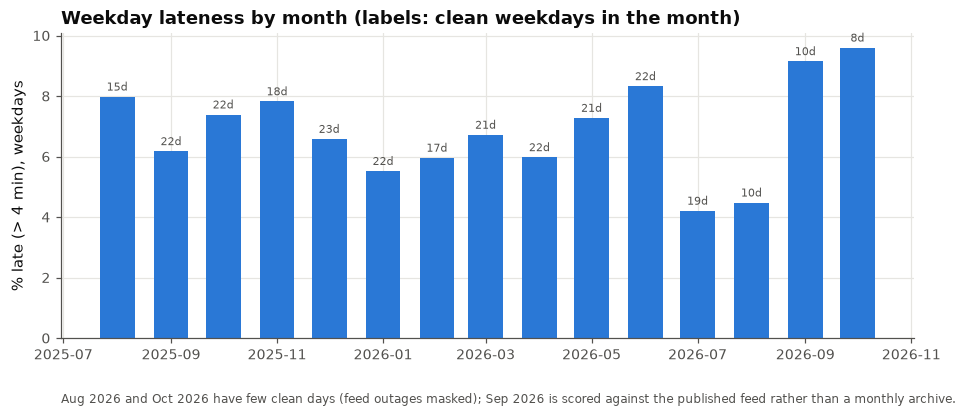

In [8]:
mo = qq("""select date_trunc('month',date) m, count(distinct date) ndays, count(*) n, avg(late4::int) late4, avg(late15::int) late15, avg(delay_signed) mean_delay
           from clean where weekday group by 1 order by 1""")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(mo.m, mo.late4 * 100, width=20, color=BLUE)
for x, y, n in zip(mo.m, mo.late4 * 100, mo.ndays):
    ax.text(x, y + 0.2, f"{n}d", ha="center", fontsize=7, color=MUTED)
ax.set_ylabel("% late (> 4 min), weekdays"); ax.set_title("Weekday lateness by month (labels: clean weekdays in the month)")
note(ax, "Aug 2026 and Oct 2026 have few clean days (feed outages masked); Sep 2026 is scored against the published feed rather than a monthly archive.")
plt.show()

## 4. Northbound accumulates twice the delay of southbound

Schedules are symmetric (a 22-stop local is 78 min NB vs 77 min SB), yet northbound
trains arrive at their last observed stop with about twice the mean delay and late share
of southbound trains, in every month of the record. The per-segment view in notebook 03
shows where that comes from.

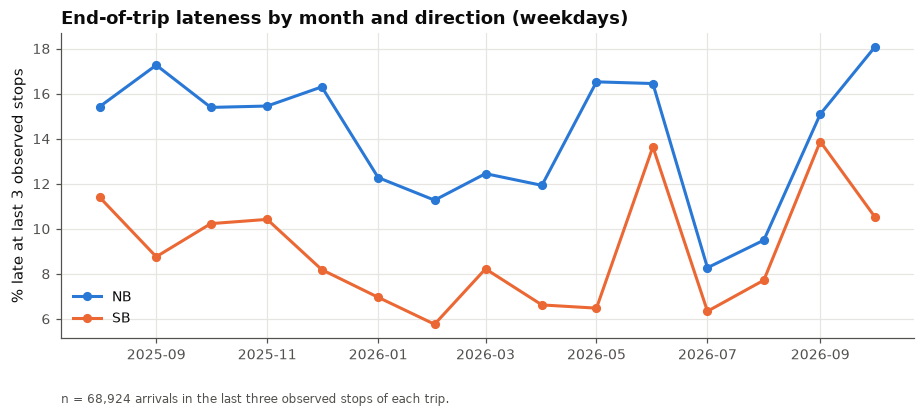

In [9]:
end = qq("""select date_trunc('month',date) m, direction, count(*) n, avg(late4::int) late4, avg(delay_signed) mean_delay
            from clean where weekday and stop_rank>=n_stops-3 group by 1,2 order by 1,2""")
fig, ax = plt.subplots(figsize=(10, 3.6))
for d, g in end.groupby("direction"):
    ax.plot(g.m, g.late4 * 100, color=DIR_COLOR[d], marker="o", label=d)
ax.set_ylabel("% late at last 3 observed stops"); ax.set_title("End-of-trip lateness by month and direction (weekdays)")
ax.legend(); note(ax, f"n = {end.n.sum():,} arrivals in the last three observed stops of each trip.")
plt.show()

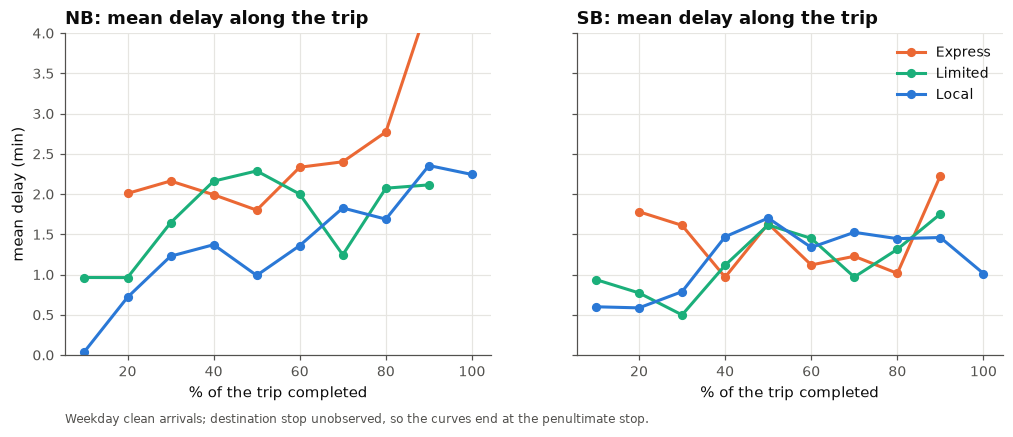

In [10]:
prof = qq("""select direction, service, round(stop_rank*1.0/n_stops, 1) frac, count(*) n, avg(delay_signed) mean_delay, avg(late4::int) late4
             from clean where weekday and service in ('Local','Express','Limited') group by 1,2,3 having count(*)>300 order by 1,2,3""")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, d in zip(axes, ["NB", "SB"]):
    for s, g in prof[prof.direction == d].groupby("service"):
        ax.plot(g.frac * 100, g.mean_delay, color=SERVICE_COLOR[s], marker="o", label=s)
    ax.set_title(f"{d}: mean delay along the trip"); ax.set_xlabel("% of the trip completed"); ax.set_ylim(0, 4)
axes[0].set_ylabel("mean delay (min)"); axes[1].legend()
note(axes[0], "Weekday clean arrivals; destination stop unobserved, so the curves end at the penultimate stop.")
plt.show()

## 5. Express trains are the least reliable service, but only northbound

Express trains skip stops but cannot overtake: with ~10-minute headways behind a local
they inherit whatever is ahead of them (notebook 03 quantifies this). Southbound
expresses are as reliable as locals.

In [11]:
svc = qq("""select case when sched_hour between 7 and 9 then 'AM peak' when sched_hour between 16 and 18 then 'PM peak' else 'off-peak' end period,
                   direction, service, count(*) n, count(distinct trip_id) trains, avg(late4::int) late4, avg(delay_signed) mean_delay
            from clean where weekday and service<>'South County' group by 1,2,3 order by 1,2,3""")
svc.assign(late4=(svc.late4*100).round(1), mean_delay=svc.mean_delay.round(2))

,period,direction,service,n,trains,late4,mean_delay
0,AM peak,NB,Express,4979,3,16.2,2.54
1,AM peak,NB,Limited,9274,3,11.4,1.90
2,AM peak,NB,Local,24472,16,6.2,1.22
3,AM peak,SB,Express,4746,3,3.9,1.15
4,AM peak,SB,Limited,9991,3,2.8,0.81
5,AM peak,SB,Local,25799,12,4.8,0.89
6,PM peak,NB,Express,6369,4,14.8,2.69
7,PM peak,NB,Limited,9986,4,9.1,2.09
8,PM peak,NB,Local,23967,18,11.4,2.14
9,PM peak,SB,Express,6398,4,5.9,1.64


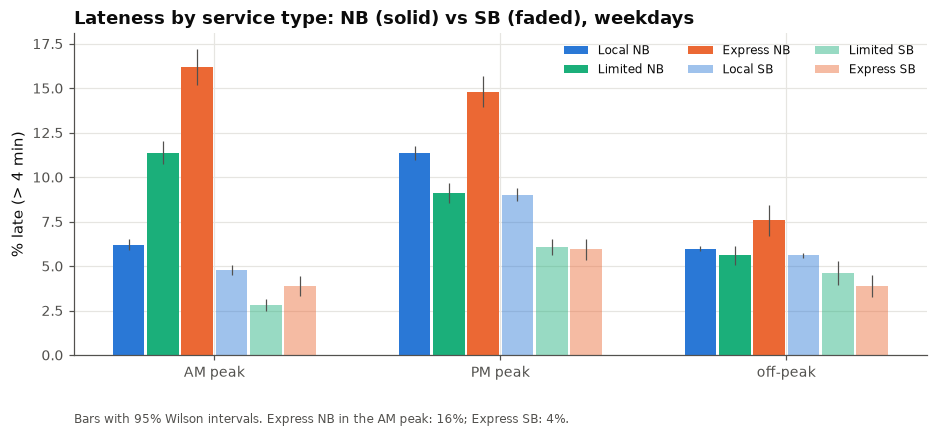

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.8))
periods = ["AM peak", "PM peak", "off-peak"]; services = ["Local", "Limited", "Express"]
w = 0.12; xs = np.arange(len(periods))
for i, d in enumerate(["NB", "SB"]):
    for j, s in enumerate(services):
        g = svc[(svc.direction == d) & (svc.service == s)].set_index("period").reindex(periods)
        x = xs + (i * 3 + j - 2.5) * w
        ax.bar(x, g.late4 * 100, width=w * 0.92, color=SERVICE_COLOR[s], alpha=1 if d == "NB" else 0.45,
               label=f"{s} {d}" if True else None)
        ax.errorbar(x, g.late4 * 100, yerr=wilson_halfwidth(g.late4, g.n) * 100, fmt="none", ecolor=MUTED, lw=0.8)
ax.set_xticks(xs); ax.set_xticklabels(periods); ax.set_ylabel("% late (> 4 min)")
ax.set_title("Lateness by service type: NB (solid) vs SB (faded), weekdays")
ax.legend(ncol=3, fontsize=8); note(ax, "Bars with 95% Wilson intervals. Express NB in the AM peak: 16%; Express SB: 4%.")
plt.show()

## 6. The train league table

Per train number: how late it is at its *last observed stop*, over all clean weekday
runs (≈ 250 runs each). Train 523 (17:22 Express NB) arrives more than four minutes
late at 22nd Street on half its runs; the midday southbound locals almost never do.

In [13]:
last = qq("""with last as (select date, trip_id, service, direction, sched_hour, delay_signed, late4, late15,
                 row_number() over (partition by date, trip_id order by stop_rank desc) rn from clean where weekday)
             select trip_id, service, direction, min(sched_hour) first_hour, count(*) runs, median(delay_signed) median_delay,
                    quantile_cont(delay_signed,0.9) p90_delay, avg(late4::int) late4, avg(late15::int) late15
             from last where rn=1 group by 1,2,3 having count(*)>=80 order by late4 desc""")
last["ci"] = wilson_halfwidth(last.late4, last.runs)
pd.concat([last.head(12), last.tail(8)]).round(3)

,trip_id,service,direction,first_hour,runs,median_delay,p90_delay,late4,late15,ci
0,523,Express,NB,17,259,3.983,11.220,0.498,0.069,0.060
1,511,Express,NB,8,263,3.783,8.860,0.373,0.038,0.058
2,507,Express,NB,7,254,2.875,7.940,0.346,0.020,0.058
3,149,Local,NB,17,266,2.983,7.042,0.346,0.038,0.057
4,409,Limited,NB,8,259,3.767,7.813,0.340,0.027,0.057
5,151,Local,NB,17,264,2.933,8.890,0.326,0.061,0.056
6,527,Express,NB,18,261,2.933,7.833,0.310,0.054,0.056
7,425,Limited,NB,18,258,1.983,7.927,0.236,0.039,0.052
8,153,Local,NB,18,265,1.900,6.920,0.234,0.042,0.051
9,421,Limited,NB,17,261,1.867,7.833,0.230,0.038,0.051


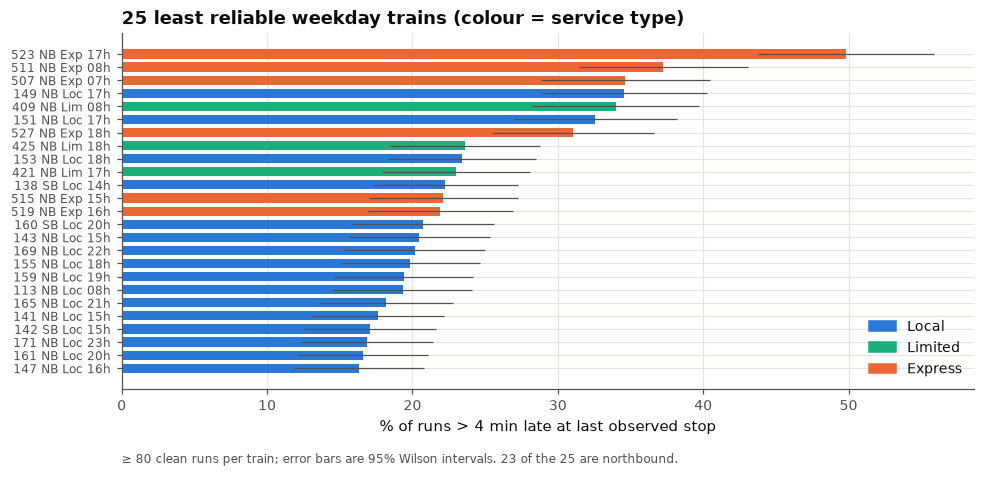

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
top = last.head(25)
cols = [SERVICE_COLOR.get(s, MUTED) for s in top.service]
ax.barh(range(len(top))[::-1], top.late4 * 100, xerr=top.ci * 100, color=cols, error_kw=dict(ecolor=MUTED, lw=0.8), height=0.7)
ax.set_yticks(range(len(top))[::-1]); ax.set_yticklabels([f"{t} {d} {s[:3]} {h:02d}h" for t, d, s, h in zip(top.trip_id, top.direction, top.service, top.first_hour)], fontsize=8)
ax.set_xlabel("% of runs > 4 min late at last observed stop")
ax.set_title("25 least reliable weekday trains (colour = service type)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERVICE_COLOR[s], label=s) for s in ["Local", "Limited", "Express"]], loc="lower right")
note(ax, "≥ 80 clean runs per train; error bars are 95% Wilson intervals. 23 of the 25 are northbound.")
plt.show()

## 7. Station profile and the timetable "sawtooth"

Median delay by station is not smooth: it alternates between ~+1 and ~0 minutes at
adjacent stations. The timetable is written in whole minutes, and some two-minute hops
(San Mateo → Hayward Park, Belmont → San Carlos southbound) are consistently run in
three, while some four-minute hops are run in three. 511's independent observations
show the same signs at the same stations, so this is the schedule, not our detector.
The magnitudes are at the one-minute precision floor, so read the *pattern*, not the
decimals.

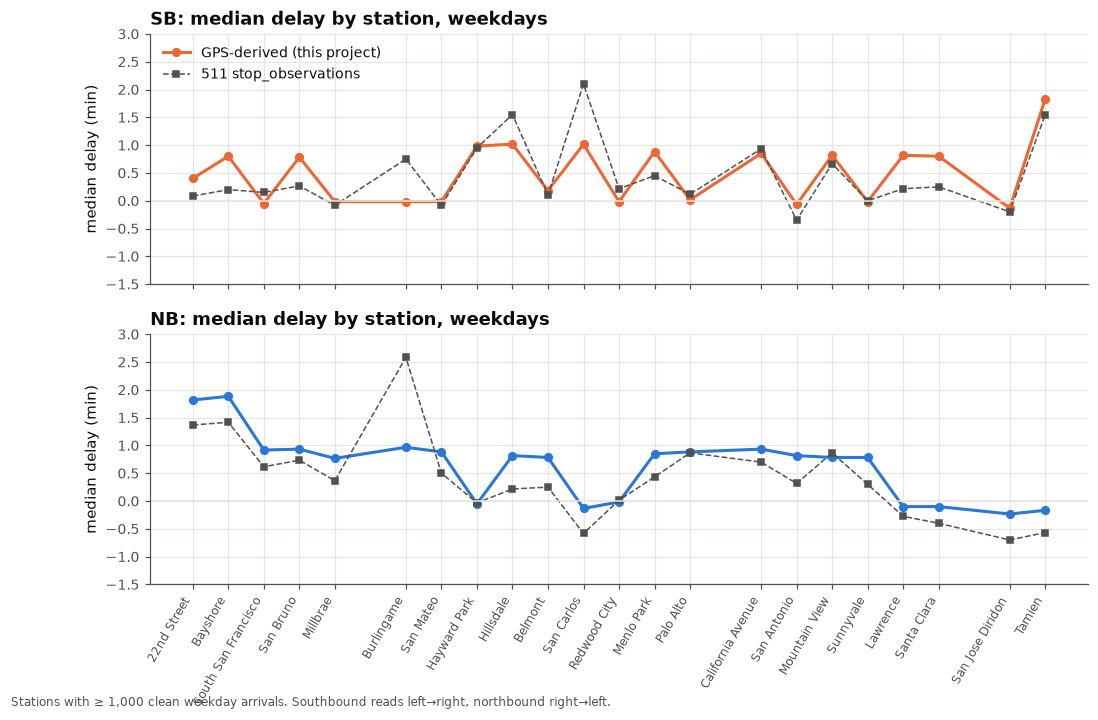

In [15]:
con.execute("""create or replace temp macro hms(s) as (split_part(s,':',1)::int*3600 + split_part(s,':',2)::int*60 + split_part(s,':',3)::int)/60.0""")
con.execute("""create or replace temp view obs511 as
  select strptime(service_date,'%Y%m%d')::date date, train trip_id, to_stop_id stop_id,
         hms(observed_arrival_time) - hms(scheduled_arrival_time) d511
  from stop_observations where try_cast(stop_sequence as int)>1 and length(observed_arrival_time)=8 and length(scheduled_arrival_time)=8""")
st = qq("""with g as (select stop_id, station, direction, count(*) n, median(delay_signed) med_gps, avg(delay_signed) mean_gps, avg(late4::int) late4_gps,
                      avg((delay_signed<=-1)::int) early_gps from clean where weekday group by 1,2,3),
           o as (select stop_id, median(d511) med_511, avg((d511>4)::int) late4_511 from obs511 where d511 between -30 and 120 and isodow(date)<=5 group by 1)
           select * from g left join o using(stop_id) where n>1000 order by direction, stop_id""")
st["ord"] = st.station.map({s: i for i, s in enumerate(STATION_ORDER)})
st = st.sort_values(["direction", "ord"])

fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, d in zip(axes, ["SB", "NB"]):
    g = st[st.direction == d]
    ax.plot(g.ord, g.med_gps, color=DIR_COLOR[d], marker="o", label="GPS-derived (this project)")
    ax.plot(g.ord, g.med_511, color=MUTED, marker="s", ms=4, lw=1, ls="--", label="511 stop_observations")
    ax.axhline(0, color=GRID, lw=1); ax.set_ylabel("median delay (min)"); ax.set_title(f"{d}: median delay by station, weekdays")
    ax.set_ylim(-1.5, 3)
axes[0].legend(loc="upper left")
axes[1].set_xticks(st.ord.unique()); axes[1].set_xticklabels([STATION_ORDER[i] for i in sorted(st.ord.unique())], rotation=60, ha="right", fontsize=8)
fig.text(0.01, -0.06, "Stations with ≥ 1,000 clean weekday arrivals. Southbound reads left→right, northbound right→left.", fontsize=8, color=MUTED)
plt.show()

In [16]:
st[["station", "direction", "n", "med_gps", "med_511", "late4_gps", "late4_511", "early_gps"]].round(2)

,station,direction,n,med_gps,med_511,late4_gps,late4_511,early_gps
0,22nd Street,NB,11162,1.82,1.37,0.17,0.19,0.03
1,Bayshore,NB,6398,1.88,1.42,0.16,0.17,0.00
2,South San Francisco,NB,9146,0.92,0.62,0.12,0.13,0.04
3,San Bruno,NB,7307,0.93,0.73,0.11,0.12,0.00
4,Millbrae,NB,10055,0.77,0.37,0.10,0.11,0.14
5,Burlingame,NB,8346,0.97,2.58,0.11,0.22,0.01
6,San Mateo,NB,11599,0.88,0.50,0.09,0.10,0.00
7,Hayward Park,NB,7299,-0.05,-0.03,0.07,0.07,0.20
8,Hillsdale,NB,10366,0.82,0.22,0.08,0.08,0.09
9,Belmont,NB,7108,0.78,0.25,0.06,0.07,0.01


## 8. Weather: rain does nothing, heat does a little

Daily weather near SFO (Open-Meteo archive). Rainy weekdays are no later than dry ones.
The hottest days (≥ 28 °C max, 18 weekdays) are late more often even after removing
each month's average, but one extreme day (2026-09-09, 36.5 °C, the 10th-worst day in
the record) carries much of that, so this is suggestive rather than established.

In [17]:
w = json.load(open("data/external/weather_sfo.json"))["daily"]
wx = pd.DataFrame({"date": pd.to_datetime(w["time"]).date, "precip": w["precipitation_sum"], "tmax": w["temperature_2m_max"]})
con.register("wx", wx)
qq("""select case when precip<0.2 then 'dry' when precip<5 then 'light rain (<5 mm)' else 'rain (>=5 mm)' end weather,
          count(distinct date) ndays, count(*) n, round(avg(late4::int),3) late4, round(avg(late15::int),4) late15
   from clean join wx using(date) where weekday group by 1 order by 1""")

,weather,ndays,n,late4,late15
0,dry,199,292836,0.066,0.0099
1,light rain (<5 mm),46,67759,0.067,0.0117
2,rain (>=5 mm),26,37041,0.075,0.0086


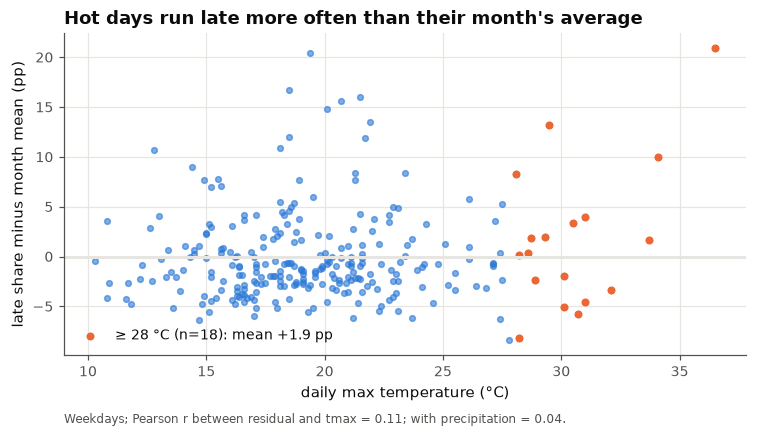

In [18]:
heat = qq("""with d as (select date, avg(late4::int) late4 from clean where weekday group by 1),
             m as (select date, late4, late4 - avg(late4) over (partition by date_trunc('month',date)) resid from d)
             select m.date, late4, resid, tmax, precip from m join wx using(date)""")
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.scatter(heat.tmax, heat.resid * 100, s=14, color=BLUE, alpha=0.6)
hot = heat[heat.tmax >= 28]
ax.scatter(hot.tmax, hot.resid * 100, s=18, color=ORANGE, label=f"≥ 28 °C (n={len(hot)}): mean +{hot.resid.mean()*100:.1f} pp")
ax.axhline(0, color=GRID); ax.set_xlabel("daily max temperature (°C)"); ax.set_ylabel("late share minus month mean (pp)")
ax.set_title("Hot days run late more often than their month's average"); ax.legend()
note(ax, f"Weekdays; Pearson r between residual and tmax = {np.corrcoef(heat.tmax, heat.resid)[0,1]:.2f}; with precipitation = {np.corrcoef(heat.precip.fillna(0), heat.resid)[0,1]:.2f}.")
plt.show()